In [45]:
import numpy as np
import pandas as pd
import torch
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import  torch.nn as nn
from sklearn.model_selection import train_test_split
from PIL import Image
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [21]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"you are using {device}")

you are using cuda


In [22]:
data = pd.read_csv("/content/fashion-mnist_train.csv")
data.head(5)

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


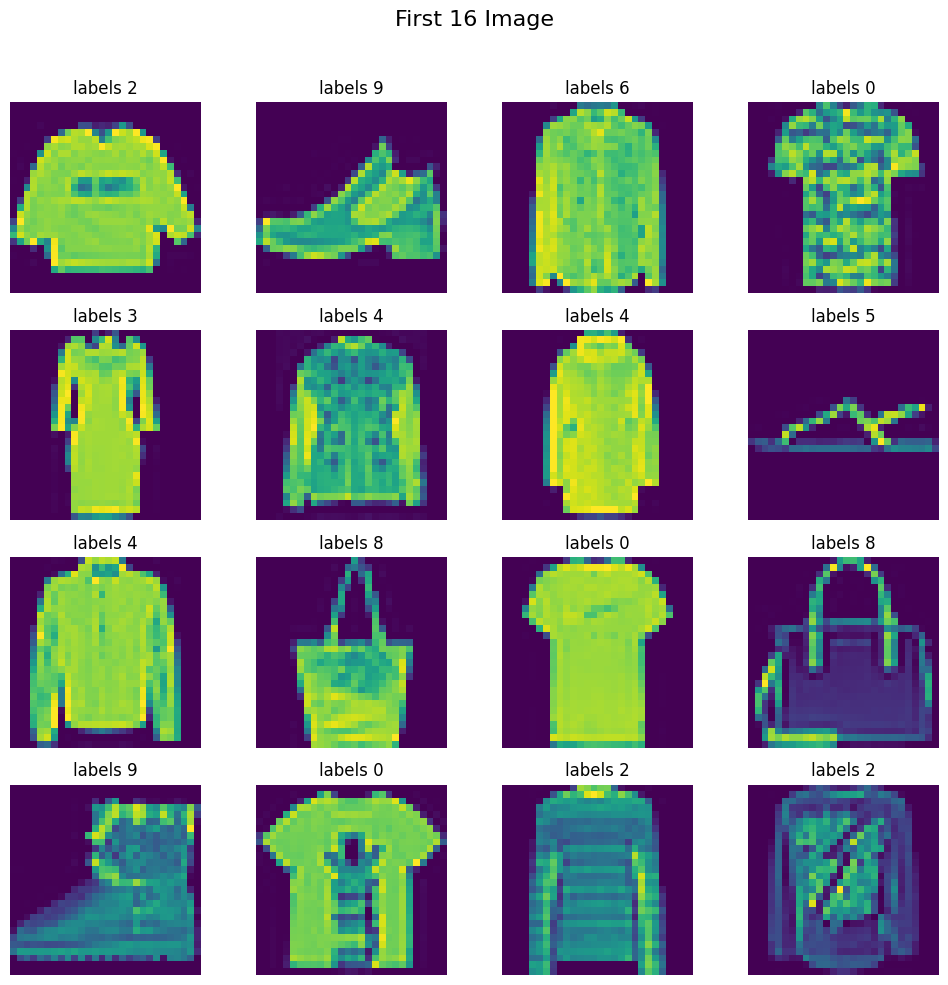

In [23]:
fig, axes = plt.subplots(4,4, figsize=(10,10))
fig.suptitle("First 16 Image", fontsize=16)

for i, ax in enumerate(axes.flat):
  img = data.iloc[i, 1:].values.reshape(28,28)
  ax.imshow(img)
  ax.axis("off")
  ax.set_title(f"labels {data.iloc[i, 0]}")


plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [24]:
X = data.iloc[:, 1:].values
y = data.iloc[:, 0].values

In [25]:
X.shape, y.shape

((60000, 784), (60000,))

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [27]:
X_train.shape

(48000, 784)

In [28]:
X_train = X_train/255.0
X_test = X_test/255.0

In [29]:
class CustomDataset(Dataset):
  def __init__(self, features, labels):
    super().__init__()

    self.features = torch.tensor(features, dtype=torch.float32)
    self.labels = torch.tensor(labels, dtype=torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self,index):
    return self.features[index], self.labels[index]

In [30]:
train_dataset = CustomDataset(X_train, y_train)
test_dataset = CustomDataset(X_test, y_test)

In [31]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory=True)

In [32]:
class MyNN(nn.Module):
  def __init__(self, num_features):
    super().__init__()

    self.model=nn.Sequential(
        nn.Linear(num_features, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10)
    )


  def forward(self,x):
    return self.model(x)

In [33]:
epochs = 100
learning_rate = 0.01

model = MyNN(X_train.shape[1])
model.to(device)

model.parameters()

critrion = nn.CrossEntropyLoss()

optimizer = optim.SGD(model.parameters(), lr = learning_rate)

In [34]:
for epoch in range(epochs):
  total_epoch_loss = 0

  for batch_features, batch_labels in train_loader:

    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    loss = critrion(outputs, batch_labels)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    total_epoch_loss = total_epoch_loss + loss.item()

  avg_loss = total_epoch_loss / len(train_loader)

  print(f"epoch {epoch+1} loss {avg_loss}")

epoch 1 loss 1.1866197965542475
epoch 2 loss 0.6465128717919191
epoch 3 loss 0.5446127930382888
epoch 4 loss 0.5008341471453508
epoch 5 loss 0.47311867132782937
epoch 6 loss 0.45620716650287313
epoch 7 loss 0.4415945148964723
epoch 8 loss 0.42908149448533855
epoch 9 loss 0.41659903088708716
epoch 10 loss 0.4045018082062403
epoch 11 loss 0.3958541015883287
epoch 12 loss 0.3850088918109735
epoch 13 loss 0.3769466870625814
epoch 14 loss 0.3683376667002837
epoch 15 loss 0.36269006184736885
epoch 16 loss 0.3553949089149634
epoch 17 loss 0.3472943053195874
epoch 18 loss 0.3405863951519132
epoch 19 loss 0.33483997821311157
epoch 20 loss 0.3288162023747961
epoch 21 loss 0.32401978532473247
epoch 22 loss 0.31854944576571387
epoch 23 loss 0.3139704701950153
epoch 24 loss 0.3091913937777281
epoch 25 loss 0.30475365433593593
epoch 26 loss 0.2993674738307794
epoch 27 loss 0.2937752587373058
epoch 28 loss 0.2909001806428035
epoch 29 loss 0.28733628512422243
epoch 30 loss 0.2832950323596597
epoch 31 

In [35]:
model.eval()

MyNN(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [43]:
total = 0
total_loss = 0
correct = 0

with torch.no_grad():
  for batch_features, batch_labels in test_loader:
    batch_features, batch_labels  = batch_features.to(device), batch_labels.to(device)


    outputs = model(batch_features)

    _,predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = total + (predicted == batch_labels).sum().item()
    total_loss = total_loss + (loss.item() * batch_labels.size(0))


  accuracy = correct / total

  avg_loss = total_loss / total

  print(f"Accuracy {accuracy}\n")
  print(f"Avarage loss {avg_loss}")









Accuracy 1.00225

Avarage loss 0.1519547700881958


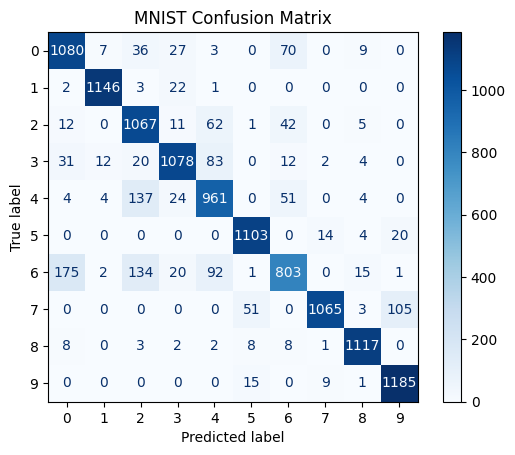

In [46]:
all_preds = []
all_labels = []

model.eval()

with torch.no_grad():

    for batch_features, batch_labels in test_loader:

        batch_features = batch_features.to(device)

        outputs = model(batch_features)

        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())

        all_labels.extend(batch_labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap="Blues")

plt.title("MNIST Confusion Matrix")

plt.show()

In [47]:
torch.save(
    model.state_dict(),
    "/content/fashion-mnist_model.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [49]:
loaded_model = MyNN(784).to(device)

loaded_model.load_state_dict(
    torch.load(
        "/content/fashion-mnist_model.pth",
        map_location=device
    )
)

loaded_model.eval()

print("Model loaded successfully!")

Model loaded successfully!


In [52]:
import pandas as pd

df = pd.read_csv('/content/fashion-mnist_test.csv')

print(df.shape)
print(df.head())
print(df.columns)

(10000, 785)
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      0       0       0       0       0       0       0       0       9   
1      1       0       0       0       0       0       0       0       0   
2      2       0       0       0       0       0       0      14      53   
3      2       0       0       0       0       0       0       0       0   
4      3       0       0       0       0       0       0       0       0   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0       8  ...       103        87        56         0         0         0   
1       0  ...        34         0         0         0         0         0   
2      99  ...         0         0         0         0        63        53   
3       0  ...       137       126       140         0       133       224   
4       0  ...         0         0         0         0         0         0   

   pixel781  pixel782  pixel783  pixel784  
0         0      

In [53]:
X_test = df.drop('label', axis=1).values
y_test = df['label'].values

print(X_test.shape)
print(y_test.shape)

(10000, 784)
(10000,)


In [54]:
X_test = X_test / 255.0

In [55]:
X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
).to(device)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
).to(device)

In [56]:
loaded_model.eval()

correct = 0
total = 0

with torch.no_grad():

    outputs = loaded_model(X_test_tensor)

    predicted = torch.argmax(outputs, dim=1)

    total += y_test_tensor.size(0)

    correct += (predicted == y_test_tensor).sum().item()

accuracy = correct / total

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 88.74%


In [57]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

index = 0

print("Predicted:", class_names[predicted[index].item()])
print("Actual:", class_names[y_test[index]])

Predicted: T-shirt/top
Actual: T-shirt/top
